In [ ]:
import torchvision, torch
import matplotlib.pyplot as plt



## Load Dataset

In [3]:
from torchvision.datasets import FashionMNIST

train_data = FashionMNIST('mnist_data',train = True, download = True)
test_data = FashionMNIST('mnist_data',train = False, download = True)

100%|██████████| 26.4M/26.4M [00:01<00:00, 22.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 342kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.27MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.9MB/s]


## Visualize Images

In [4]:
images, labels = train_data.data, train_data.targets
str_labels = list(train_data.class_to_idx.keys())
(images[0].shape)

torch.Size([28, 28])

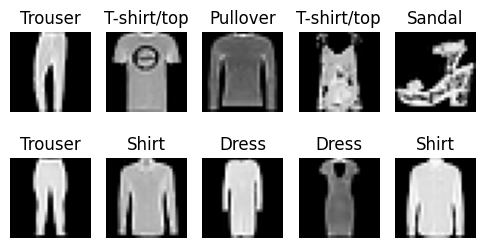

In [5]:
fig, axs = plt.subplots(2, 5, figsize = (6,3))
torch.manual_seed(3)

for ax in axs.flatten():

  r = torch.randint(100, (1,1)).item()
  ax.imshow(images[r], cmap= 'gray')
  ax.set_title(str_labels[labels[r].item()])
  ax.axis('off')


## Prepare The Dataset

In [6]:
from torchvision import transforms
from torch.utils.data import DataLoader, random_split

# Converting to tensor # (0.286, 0.353)
transform_train = transforms.Compose(
    [transforms.ToTensor(),                 # Scale and unsqueeze
     transforms.Normalize((.286), (.353)),
     transforms.RandomHorizontalFlip(),          # clothes are mostly symmetric
     transforms.RandomRotation(10),              # small rotations
     ])

transform_val = transforms.Compose(
    [transforms.ToTensor(),                 # Scale and unsqueeze
     transforms.Normalize((.286), (.353)),
     ])

train_data.transform = transform_train
test_data.transform = transform_val

# Get Val data
torch.manual_seed(2)
val_data, test_data = random_split(test_data, [.5, .5])

In [7]:
train_loader = DataLoader(train_data, 256, shuffle= True)
test_loader = DataLoader(test_data, 256, shuffle= False)
val_loader = DataLoader(val_data, 256, shuffle= False)
len(train_loader.dataset), len(test_loader.dataset), len(val_loader.dataset)

(60000, 5000, 5000)

## Building the Neural Network

In [8]:
from torch import nn
from torch.nn import functional as F

class Mnist_Network(nn.Module):

  def __init__(self):
    super().__init__()

    # first conv layer
    self.conv1 = nn.Conv2d(1,80,3, padding=1)
    self.bn1 = nn.BatchNorm2d(80)

    # second conv layer
    self.conv2 = nn.Conv2d(80, 160, 3, padding=1)
    self.bn2 = nn.BatchNorm2d(160)

    # third conv layer
    self.conv3 = nn.Conv2d(160, 320, 3, padding=1)
    self.bn3 = nn.BatchNorm2d(320)

    # forth conv layer
    self.conv4 = nn.Conv2d(320, 400, 3, padding=1)
    self.bn4 = nn.BatchNorm2d(400)

    # pooling & dropout
    self.max_pool = nn.MaxPool2d(2)
    self.dropout = nn.Dropout(.5)

    # fully connected layers
    self.fc1 = nn.Linear(400 * 3 * 3 , 100)
    self.fc2 = nn.Linear(100, 10)

  def forward(self, x):
    x = self.max_pool(F.relu(self.bn1(self.conv1(x))))
    x = self.max_pool(F.relu(self.bn2(self.conv2(x))))
    x = self.max_pool(F.relu(self.bn3(self.conv3(x))))
    x = self.dropout(x)
    x = F.relu(self.bn4(self.conv4(x)))
    x = x.view(x.size(0), -1)
    x = F.relu(self.fc1(x))
    x = self.dropout(x)
    x = self.fc2(x)


    return x


## Check Architecture

In [14]:
# ! pip install torchinfo
from torchinfo import summary

model = Mnist_Network()
summary(model, (32, 1, 28, 28))

Layer (type:depth-idx)                   Output Shape              Param #
Mnist_Network                            [32, 10]                  --
├─Conv2d: 1-1                            [32, 80, 28, 28]          800
├─BatchNorm2d: 1-2                       [32, 80, 28, 28]          160
├─MaxPool2d: 1-3                         [32, 80, 14, 14]          --
├─Conv2d: 1-4                            [32, 160, 14, 14]         115,360
├─BatchNorm2d: 1-5                       [32, 160, 14, 14]         320
├─MaxPool2d: 1-6                         [32, 160, 7, 7]           --
├─Conv2d: 1-7                            [32, 320, 7, 7]           461,120
├─BatchNorm2d: 1-8                       [32, 320, 7, 7]           640
├─MaxPool2d: 1-9                         [32, 320, 3, 3]           --
├─Dropout: 1-10                          [32, 320, 3, 3]           --
├─Conv2d: 1-11                           [32, 400, 3, 3]           1,152,400
├─BatchNorm2d: 1-12                      [32, 400, 3, 3]        

## Training phase

In [9]:
device = ('cuda' if torch.cuda.is_available() else 'cpu')
device

'cpu'

In [10]:
from torch.optim import AdamW
torch.manual_seed(2)

model = Mnist_Network()
model.to(device)
optimizer = AdamW(model.parameters(), .001, weight_decay= .02)
criterian = nn.CrossEntropyLoss()

# Other parameters
epochs = 30
best_val_acc = 0
patience = 6
p_counter = 0
model_path = 'model_FashionMNIST.pth'


# Accuracy func
def calc_acc(model, test_loader):
  with torch.no_grad():
    model.eval()

    preds = []
    labels = []
    loss = 0
    for images, targets in test_loader:
      images, targets = images.to(device), targets.to(device)

      outputs = model(images)
      loss += criterian(outputs, targets)
      preds.append(outputs)
      labels.append(targets)

    preds = torch.concat(preds)
    labels = torch.concat(labels)
    acc = (preds.argmax(1) == labels).float().mean().item()
    loss /= len(test_loader)

  return acc, round(loss.item(), 4)




In [17]:
import time
torch.manual_seed(2)

s_time = time.time()

for epoch in range(1, epochs + 1):

  train_loss = 0
  model.train()
  for i, (images, targets) in enumerate(train_loader):

    # Forward
    images, targets = images.to(device), targets.to(device)

    outputs = model(images)
    loss = criterian(outputs, targets)
    train_loss += loss

    # Backward
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()



  # Checkpoint
  acc, val_loss = calc_acc(model, val_loader)

  # print metrics
  tran_loss = (train_loss/ len(train_loader)).item()
  info1 = f'{str(epoch).zfill(2)}/{epochs}: train loss = {tran_loss:.4f}, val loss = {val_loss}'

  if acc > best_val_acc:
    best_val_acc = acc
    p_counter = 0
    torch.save(model.state_dict(), model_path)
    print(f'{info1}, val accuracy = {acc:.4f}')
  else:
    p_counter += 1
    print(f'{info1}')

  # Earlystopping
  if p_counter == patience:
    print('Earlystopping has been activated.')

    # Restore the best model
    model.load_state_dict(torch.load(model_path))
    break



e_time = time.time()
print(f'\n\nTotal training time: {(int(e_time - s_time)/ 60):.2f} minutes')

01/30: train loss = 0.6102, val loss = 0.4009, val accuracy = 0.8506
02/30: train loss = 0.4000, val loss = 0.3397, val accuracy = 0.8716
03/30: train loss = 0.3554, val loss = 0.2946, val accuracy = 0.8894
04/30: train loss = 0.3271, val loss = 0.2807, val accuracy = 0.8962
05/30: train loss = 0.3083, val loss = 0.2694, val accuracy = 0.9016
06/30: train loss = 0.2947, val loss = 0.2705
07/30: train loss = 0.2825, val loss = 0.2495, val accuracy = 0.9120
08/30: train loss = 0.2718, val loss = 0.2594
09/30: train loss = 0.2658, val loss = 0.2505
10/30: train loss = 0.2575, val loss = 0.2306, val accuracy = 0.9134
11/30: train loss = 0.2462, val loss = 0.2325, val accuracy = 0.9144
12/30: train loss = 0.2423, val loss = 0.2504
13/30: train loss = 0.2361, val loss = 0.2303, val accuracy = 0.9162
14/30: train loss = 0.2306, val loss = 0.2422
15/30: train loss = 0.2232, val loss = 0.2471
16/30: train loss = 0.2199, val loss = 0.2172, val accuracy = 0.9210
17/30: train loss = 0.2142, val lo

In [12]:
model.load_state_dict(torch.load('model_FashionMNIST_92.pth', map_location= torch.device('cpu')))
calc_acc(model,test_loader)[0]

0.9323999881744385